# BiasLens · Final Production Predictions

**One input text → Four independent bias predictions**

This notebook brings together the **four already-trained and approved Logistic Regression pipelines**. It performs **inference only**

| Bias type | Approved model |
|---|---|
| **Linguistic** | Word + Character TF-IDF + Logistic Regression |
| **Gender** | TF-IDF + Logistic Regression |
| **Racial** | TF-IDF + Logistic Regression |
| **Context** | TF-IDF + Logistic Regression |

**Notebook sections:** Setup & Model Loading · Prediction Functions · API Prediction · Validation · Sanity Checks · Prediction Examples · Final Demo

> Each model is a separate binary classifier. More than one bias type can be detected for the same text. The model outputs are statistical predictions, not ground-truth judgments.

## 1. Setup & Model Loading

In [1]:
from pathlib import Path
import importlib
import json
import sys

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Find the project root without relying on a machine-specific absolute path.
PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "models").is_dir() and (p / "notebooks").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "BiasLens root not found. Run this notebook from the BiasLens project folder."
    )

MODELS_DIR = PROJECT_ROOT / "models"
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)
print("Models folder:", MODELS_DIR)
print("Mode: INFERENCE ONLY (no retraining)")

Project root: /Users/sarahaltaleb/Documents/GitHub/BiasLens
Models folder: /Users/sarahaltaleb/Documents/GitHub/BiasLens/models
Mode: INFERENCE ONLY (no retraining)


### 1.1 Approved model inventory

In [2]:
MODEL_FILES = {
    "linguistic_bias": "linguistic_bias_lr_word_char.joblib",
    "gender_bias": "gender_bias_lr.joblib",
    "racial_bias": "racial_bias_lr.joblib",
    "context_bias": "text_level_bias_logistic_regression_c1.joblib",
}

BIAS_NAMES = {
    "linguistic_bias": "Linguistic Bias",
    "gender_bias": "Gender Bias",
    "racial_bias": "Racial Bias",
    "context_bias": "Context Bias",
}

inventory = pd.DataFrame([
    {
        "Bias": BIAS_NAMES[bias],
        "Artifact": filename,
        "Exists": (MODELS_DIR / filename).is_file(),
    }
    for bias, filename in MODEL_FILES.items()
])
display(inventory)

missing = [filename for filename in MODEL_FILES.values()
           if not (MODELS_DIR / filename).is_file()]
if missing:
    raise FileNotFoundError(
        "Required approved LR model file(s) missing in models/: "
        + ", ".join(missing)
        + ". Export the selected existing pipeline from its modeling notebook."
    )

print("PASS — all four approved model files are present")

,Bias,Artifact,Exists
0,Linguistic Bias,linguistic_bias_lr_word_char.joblib,True
1,Gender Bias,gender_bias_lr.joblib,True
2,Racial Bias,racial_bias_lr.joblib,True
3,Context Bias,text_level_bias_logistic_regression_c1.joblib,True


PASS — all four approved model files are present


### 1.2 Load the existing pipelines

In [7]:
import importlib

importlib.import_module("src.preprocessing")

MODELS = {}
POSITIVE_CLASS_INDEX = {}

for bias, filename in MODEL_FILES.items():
    model = joblib.load(MODELS_DIR / filename)
    if not isinstance(model, Pipeline):
        raise TypeError(f"{bias}: expected the FULL fitted sklearn Pipeline.")
    if not isinstance(model.steps[-1][1], LogisticRegression):
        raise TypeError(f"{bias}: final estimator is not LogisticRegression.")
    if not hasattr(model, "predict_proba"):
        raise TypeError(f"{bias}: saved pipeline has no predict_proba().")

    classes = np.asarray(model.classes_)
    if set(classes.tolist()) != {0, 1}:
        raise ValueError(f"{bias}: expected binary labels 0/1; found {classes}.")

    MODELS[bias] = model
    POSITIVE_CLASS_INDEX[bias] = int(np.flatnonzero(classes == 1)[0])
    print(f"Loaded: {BIAS_NAMES[bias]} — {filename}")

print("\nPASS — four fitted Logistic Regression pipelines loaded")

Loaded: Linguistic Bias — linguistic_bias_lr_word_char.joblib
Loaded: Gender Bias — gender_bias_lr.joblib
Loaded: Racial Bias — racial_bias_lr.joblib
Loaded: Context Bias — text_level_bias_logistic_regression_c1.joblib

PASS — four fitted Logistic Regression pipelines loaded


## 2. Prediction Functions

**Original input text → the four existing pipelines.** Each pipeline applies its *own* saved fitted preprocessing and feature extraction internally. 
`predicted_label` uses the original training convention: `0 = Unbiased`, `1 = Biased`. Default decision threshold: **0.50**.

In [8]:
def _check_text(text):
    if not isinstance(text, str) or not text.strip():
        raise ValueError("Text must be a non-empty string.")
    return text  # Preserve the exact original text.


def _check_threshold(threshold):
    if isinstance(threshold, bool) or not isinstance(threshold, (int, float)):
        raise ValueError("Threshold must be numeric.")
    if not np.isfinite(threshold) or not 0 < threshold < 1:
        raise ValueError("Threshold must be between 0 and 1 (exclusive).")
    return float(threshold)


def predict_batch(texts, threshold=0.5):
    """Predict all four independent labels for each text; inference only."""
    if not isinstance(texts, (list, tuple)) or not texts:
        raise ValueError("Provide a non-empty list or tuple of text strings.")
    texts = [_check_text(t) for t in texts]
    threshold = _check_threshold(threshold)

    scores_by_bias = {}
    for bias, model in MODELS.items():
        probabilities = np.asarray(model.predict_proba(texts), dtype=float)
        if probabilities.shape != (len(texts), 2):
            raise RuntimeError(f"{bias}: unexpected probability array shape.")
        class_1_scores = probabilities[:, POSITIVE_CLASS_INDEX[bias]]
        if not np.isfinite(class_1_scores).all():
            raise RuntimeError(f"{bias}: model returned a non-finite score.")
        if ((class_1_scores < 0) | (class_1_scores > 1)).any():
            raise RuntimeError(f"{bias}: model score must be between 0 and 1.")
        scores_by_bias[bias] = class_1_scores

    output = []
    for i, text in enumerate(texts):
        predictions = {}
        for bias in MODEL_FILES:
            probability = float(scores_by_bias[bias][i])
            label = int(probability >= threshold)
            predictions[bias] = {
                "probability": round(probability, 4),
                "predicted_label": label,
                "prediction": "Biased" if label else "Unbiased",
            }

        output.append({
            "text": text,
            "threshold": threshold,
            "predictions": predictions,
            "detected_biases": [
                bias for bias, pred in predictions.items()
                if pred["predicted_label"] == 1
            ],
        })

    return output


def analyze_text(text, threshold=0.5):
    """Unified inference: one text -> four independent bias results."""
    return predict_batch([text], threshold=threshold)[0]

print("PASS — inference functions ready")

PASS — inference functions ready


## 3. API Prediction (JSON-ready)

A lightweight Python interface for the upcoming `src/predict.py` and Streamlit integration.

In [9]:
def api_predict(payload):
    """Accept {'text': str, 'threshold': optional float}; return JSON-ready dict."""
    if not isinstance(payload, dict) or "text" not in payload:
        raise ValueError("Payload must be a dictionary containing 'text'.")
    return analyze_text(payload["text"], payload.get("threshold", 0.5))

sample_request = {"text": "The committee announced its decision yesterday."}
sample_response = api_predict(sample_request)
print(json.dumps(sample_response, indent=2, ensure_ascii=False))

{
  "text": "The committee announced its decision yesterday.",
  "threshold": 0.5,
  "predictions": {
    "linguistic_bias": {
      "probability": 0.4298,
      "predicted_label": 0,
      "prediction": "Unbiased"
    },
    "gender_bias": {
      "probability": 0.5109,
      "predicted_label": 1,
      "prediction": "Biased"
    },
    "racial_bias": {
      "probability": 0.6088,
      "predicted_label": 1,
      "prediction": "Biased"
    },
    "context_bias": {
      "probability": 0.3391,
      "predicted_label": 0,
      "prediction": "Unbiased"
    }
  },
  "detected_biases": [
    "gender_bias",
    "racial_bias"
  ]
}


## 4. Validation — Integration Integrity

These checks verify that **the saved models load correctly and the prediction interface is consistent**.

In [10]:
assert len(MODELS) == 4
assert list(sample_response["predictions"]) == list(MODEL_FILES)
assert sample_response["text"] == sample_request["text"]
assert json.loads(json.dumps(sample_response)) == sample_response

for bias, model in MODELS.items():
    raw = model.predict_proba([sample_request["text"]])
    expected = float(raw[0, POSITIVE_CLASS_INDEX[bias]])
    item = sample_response["predictions"][bias]
    assert np.isclose(item["probability"], expected, atol=0.000051), bias
    assert item["predicted_label"] == int(expected >= 0.5), bias
    assert item["prediction"] == (
        "Biased" if item["predicted_label"] else "Unbiased"
    ), bias

print("PASS — artifact loading, label mapping, JSON serialization and prediction consistency")

PASS — artifact loading, label mapping, JSON serialization and prediction consistency


## 5. Sanity Checks

In [11]:
for invalid in ("", "   ", None, 123):
    try:
        analyze_text(invalid)
    except ValueError:
        pass
    else:
        raise AssertionError(f"Invalid text was accepted: {invalid!r}")

for bad_threshold in (-0.1, 1.1, "0.5", None):
    try:
        analyze_text("A valid text", threshold=bad_threshold)
    except ValueError:
        pass
    else:
        raise AssertionError(f"Invalid threshold was accepted: {bad_threshold!r}")

text = "The school announced a new schedule."
assert analyze_text(text) == analyze_text(text)

batch = predict_batch([text, "The public report was published today."])
assert len(batch) == 2
assert all(len(item["predictions"]) == 4 for item in batch)
assert all(set(item["detected_biases"]).issubset(MODEL_FILES) for item in batch)

print("PASS — input validation, repeatability, independent predictions and batch mode")

PASS — input validation, repeatability, independent predictions and batch mode


## 6. Prediction Examples

These sentences are **examples for a live demonstration**, not an annotated test set. The models may disagree with a reader or miss a bias category; avoid interpreting example scores as validated performance metrics.

The score in each cell is the **model output for label 1**, not a directly comparable measure of severity across the four separately trained models.

In [12]:
example_texts = [
    "The school published the examination timetable.",
    "Women are naturally less capable of leading engineering teams.",
    "People from that ethnic group should never be trusted.",
    "The committee reviewed all applications using the same criteria.",
    "Everyone in that neighborhood is dishonest.",
    "The annual report was released on Monday.",
]

example_results = predict_batch(example_texts)
rows = []
for result in example_results:
    row = {"Input Text": result["text"]}
    for bias, pred in result["predictions"].items():
        row[BIAS_NAMES[bias]] = (
            f"{pred['prediction']} ({pred['probability']:.4f})"
        )
    rows.append(row)


examples_df = pd.DataFrame(rows)
with pd.option_context("display.max_colwidth", 115):
    display(examples_df)

,Input Text,Linguistic Bias,Gender Bias,Racial Bias,Context Bias
0,The school published the examination timetable.,Unbiased (0.3596),Unbiased (0.4284),Biased (0.6715),Unbiased (0.3237)
1,Women are naturally less capable of leading engineering teams.,Biased (0.7066),Biased (0.7163),Biased (0.5517),Unbiased (0.4932)
2,People from that ethnic group should never be trusted.,Unbiased (0.3657),Unbiased (0.4139),Biased (0.5280),Unbiased (0.4874)
3,The committee reviewed all applications using the same criteria.,Unbiased (0.3569),Unbiased (0.1830),Unbiased (0.3752),Biased (0.5850)
4,Everyone in that neighborhood is dishonest.,Unbiased (0.4275),Unbiased (0.4394),Biased (0.5498),Unbiased (0.3893)
5,The annual report was released on Monday.,Unbiased (0.1647),Unbiased (0.2620),Biased (0.5366),Unbiased (0.3058)


### Semantic Sanity Check — Key Findings

Six manually selected examples were used to qualitatively examine the behavior of the four independent bias classifiers.

- **3 of 6 targeted predictions** were consistent with the manually assigned expectations.
- The **Racial Bias classifier** produced potential false positives on two neutral statements.
- The **Context Bias classifier** flagged a seemingly fair statement as biased.
- The **Gender Bias classifier** correctly identified an explicitly biased statement and classified a statement rejecting gender bias as unbiased.

**Limitations:** These examples are qualitative checks, not a representative evaluation dataset. The observed mismatches highlight possible weaknesses in semantic understanding and generalization. No model parameters or decision thresholds were changed based on these examples.

**Conclusion:** The inference pipeline functions correctly, but prediction quality varies across bias categories and text contexts.

## 7. Final Demo — One Text, Four Predictions

In [15]:
# Change only this sentence during the presentation.
DEMO_TEXT = "Women should not be responsible for leading engineering teams."

demo_result = analyze_text(DEMO_TEXT)
final_table = pd.DataFrame([
    {
        "Bias Type": BIAS_NAMES[bias],
        "Prediction": pred["prediction"],
        "Bias Score": pred["probability"],
    }
    for bias, pred in demo_result["predictions"].items()
])

print("BIASLENS  |  FINAL PREDICTIONS")
print("Input:", demo_result["text"])
print("Detected categories:",
      ", ".join(BIAS_NAMES[b] for b in demo_result["detected_biases"])
      if demo_result["detected_biases"] else "None at threshold 0.50")

display(final_table.style.format({"Bias Score": "{:.4f}"}))

BIASLENS  |  FINAL PREDICTIONS
Input: Women should not be responsible for leading engineering teams.
Detected categories: Linguistic Bias, Gender Bias, Racial Bias


,Bias Type,Prediction,Bias Score
0,Linguistic Bias,Biased,0.6161
1,Gender Bias,Biased,0.8735
2,Racial Bias,Biased,0.6389
3,Context Bias,Unbiased,0.4449


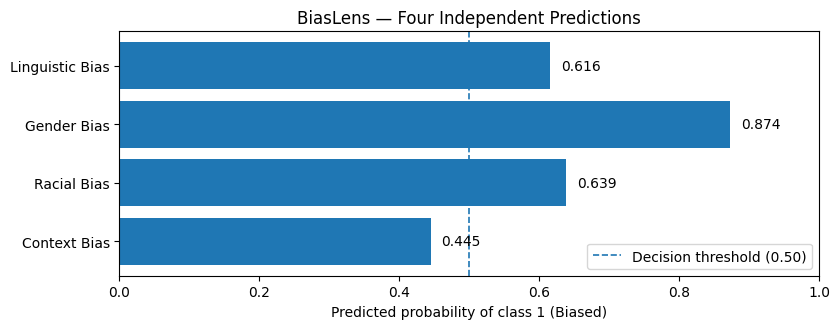

In [16]:
# Display four separate classifier outputs — not a severity ranking.
fig, ax = plt.subplots(figsize=(8.5, 3.4))
y = np.arange(len(final_table))
ax.barh(y, final_table["Bias Score"])
ax.axvline(demo_result["threshold"], linestyle="--", linewidth=1.2,
           label=f"Decision threshold ({demo_result['threshold']:.2f})")
ax.set_yticks(y, final_table["Bias Type"])
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("Predicted probability of class 1 (Biased)")
ax.set_title("BiasLens — Four Independent Predictions")
ax.legend(loc="lower right")
for i, score in enumerate(final_table["Bias Score"]):
    ax.text(min(score + 0.015, 0.98), i, f"{score:.3f}", va="center")
plt.tight_layout()
plt.show()

In [18]:

print(json.dumps(api_predict({"text": DEMO_TEXT}), indent=2, ensure_ascii=False))

{
  "text": "Women should not be responsible for leading engineering teams.",
  "threshold": 0.5,
  "predictions": {
    "linguistic_bias": {
      "probability": 0.6161,
      "predicted_label": 1,
      "prediction": "Biased"
    },
    "gender_bias": {
      "probability": 0.8735,
      "predicted_label": 1,
      "prediction": "Biased"
    },
    "racial_bias": {
      "probability": 0.6389,
      "predicted_label": 1,
      "prediction": "Biased"
    },
    "context_bias": {
      "probability": 0.4449,
      "predicted_label": 0,
      "prediction": "Unbiased"
    }
  },
  "detected_biases": [
    "linguistic_bias",
    "gender_bias",
    "racial_bias"
  ]
}
